In [1]:
import sklearn

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_csv("tips.csv")

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
X = df[["total_bill"]]
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

len(X_train)

**Why hold out 30%?**


We grade on data the model has never seen because testing on training data  can make the model look better than it is . While, holding out 30% allows us to test predictions on unseen data.  The key rule is never evaluate ontraing data and never train on test data to provide an honest evaluation.

In [5]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.4291782688312412


In [6]:
print(model.coef_, model.intercept_)

[0.10889371] 0.8769576391532707


Each extra dollar of bill adds about 0.11 dollars to the tip.

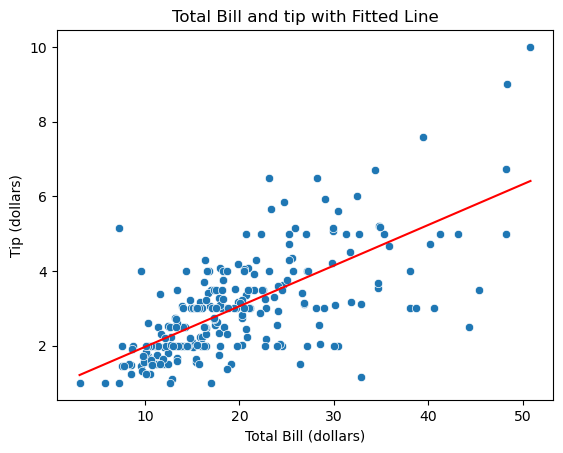

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt 
df["predicted_tip"] = model.predict(X)

sns.scatterplot(data=df, x="total_bill", y="tip")
sns.lineplot(data=df, x=df["total_bill"], y = "predicted_tip", color="red")

plt.title("Total Bill and tip with Fitted Line")
plt.xlabel("Total Bill (dollars)")
plt.ylabel("Tip (dollars)")

plt.show()

In [8]:
from sklearn.datasets import load_iris
iris = load_iris (as_frame=True)

In [9]:
iris.frame.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [10]:
iris.frame.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [11]:
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [12]:
len(X_train)

105

In [13]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print(knn.score(X_test, y_test))

1.0


In [14]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X_train, y_train)

print(tree.score(X_test, y_test))

1.0


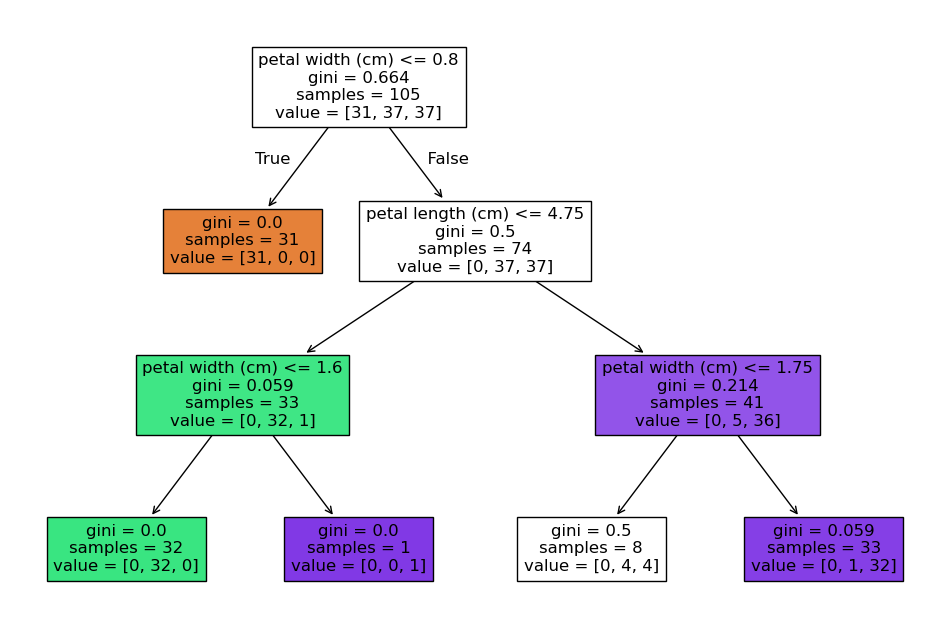

In [15]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize= (12,8))
plot_tree(tree, feature_names=iris.feature_names, filled=True)
plt.show()

The root split depends on whether the petal width is 0.8cm or less. 

In [16]:
new_tree = DecisionTreeClassifier()
new_tree.fit(X_train, y_train)

print("Model|  Train|     Test")
print("Shallow", tree.score(X_train, y_train),tree.score(X_test, y_test))
print("Unlimited", new_tree.score(X_train, y_train),new_tree.score(X_test, y_test))

Model|  Train|     Test
Shallow 0.9523809523809523 1.0
Unlimited 1.0 1.0


**Observation**

The unlimited tree improved training accuracy but both trees had the same test accuracy.

In [17]:
new_flower = pd.DataFrame([[4.5, 3.9, 2.6, 0.9]], columns=iris.feature_names)
prediction = knn.predict(new_flower)
print(iris.target_names[prediction])

['setosa']


The invented flower measurements I used were sepal length:4.5cm, sepal width:3.9cm, petal length: 2.6cm, and petal width:0.9cm. The kNN model predicted my new flower is a setosa. I would choose the kNN model. This model had a test accuracy of  100% on the test set. This model could fail if the flowers are not measured correctly. One bias risk if this were a model about people instead of flowers is that some groups may be underrepresented, which could cause less accurate predictions.

https://github.com/jazzminowens/cs82a-portfolio